In [ ]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
df = pd.read_csv(next(Path("../data/raw").glob("*.csv")))

target = "sleep_debt_category"
order = ["Optimal Recovery", "Mild Deficit", "Moderate Debt", "Severe Sleep Debt"]
palette = dict(zip(order, ["#4c9f70", "#e0c341", "#e08a3c", "#c0392b"]))
num_cols = [c for c in df.select_dtypes("number").columns if c != "blue_light_filter_active"]
cat_cols = [c for c in df.select_dtypes(exclude="number").columns if c not in (target, "user_id")] + ["blue_light_filter_active"]

# 1.Biểu đồ phân bố biến mục tiêu
--> Nhãn mất cân bằng (Moderate 52,5%, Severe chỉ 7,6%)

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(data=df, x=target, order=order, palette=palette, hue=target, legend=False, ax=ax)
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())} ({p.get_height()/len(df):.1%})",
                (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
ax.set_title("Phân bố sleep_debt_category")
ax.set_xlabel("")
plt.show()

# 2.Biểu đồ histogram các cột số

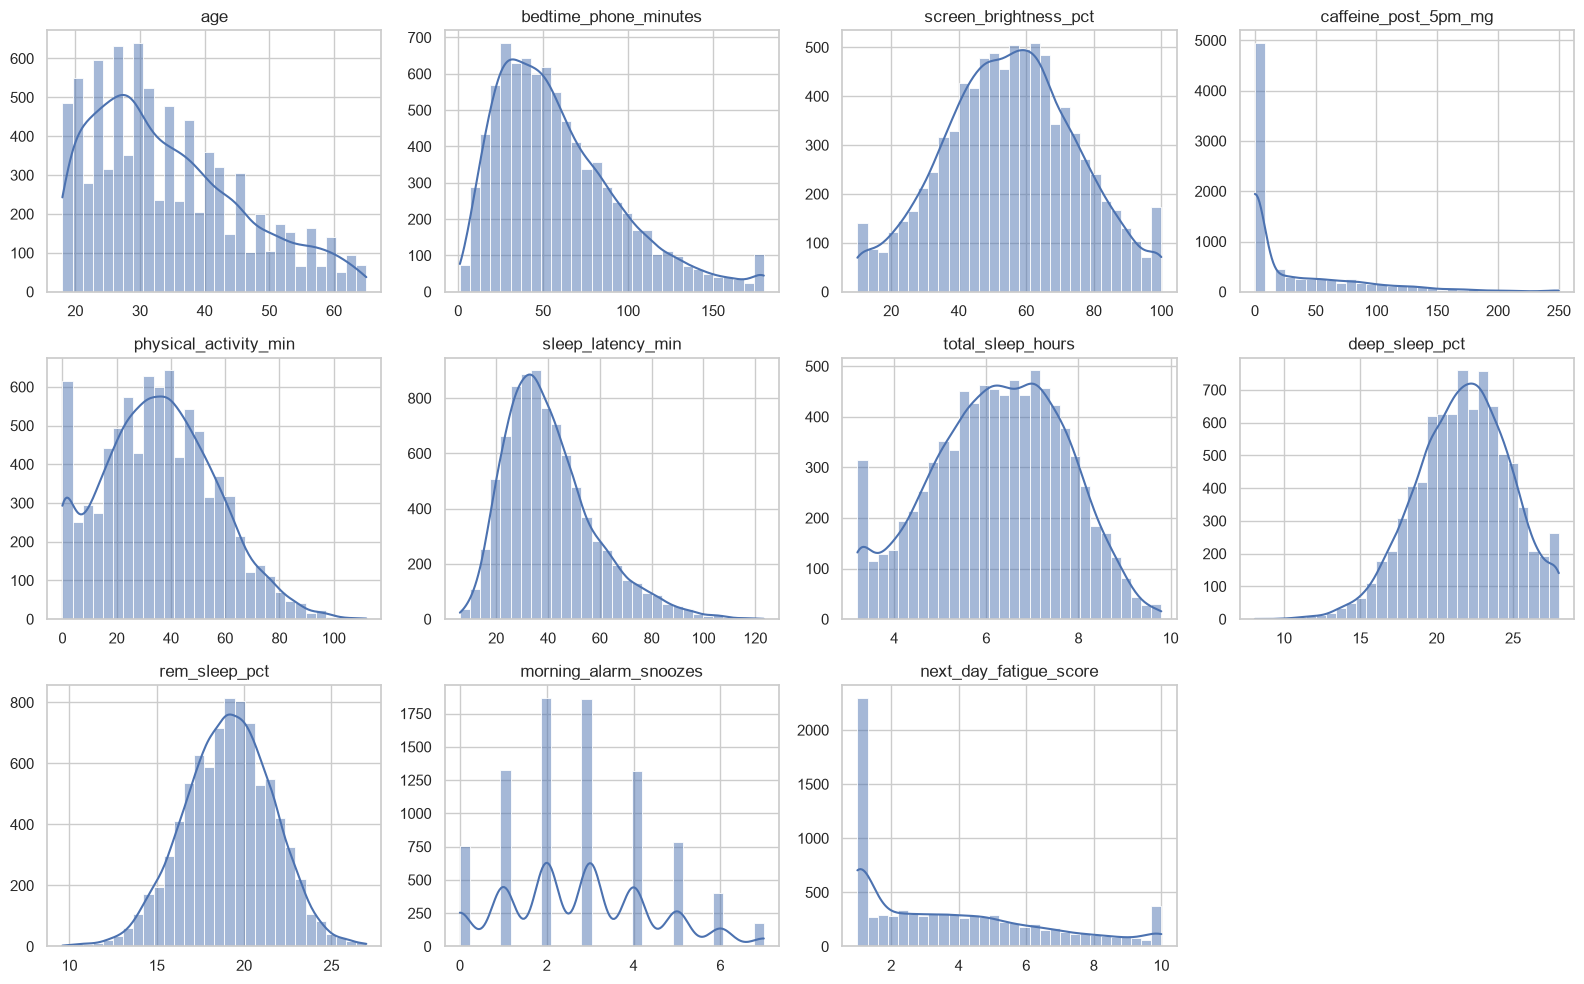

In [15]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.flat, num_cols):
    sns.histplot(df[col], bins=30, kde=True, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("")
for ax in list(axes.flat)[len(num_cols):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.flat, num_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
    ax.set_ylabel("")
for ax in list(axes.flat)[len(num_cols):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
corr = df[num_cols + ["blue_light_filter_active"]].corr()

plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 8})
plt.title("Ma trận tương quan")
plt.show()

In [ ]:
fig, axes = plt.subplots(3, 4, figsize=(17, 11))
for ax, col in zip(axes.flat, num_cols):
    sns.boxplot(data=df, x=target, y=col, order=order, palette=palette,
                hue=target, legend=False, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_xticks(range(4), ["Optimal", "Mild", "Moderate", "Severe"])
for ax in list(axes.flat)[len(num_cols):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, col in zip(axes.flat, cat_cols):
    ct = pd.crosstab(df[col], df[target], normalize="index")[order]
    ct = ct.loc[ct["Severe Sleep Debt"].sort_values().index]
    ct.plot.barh(stacked=True, color=[palette[o] for o in order], ax=ax, legend=False)
    ax.set_title(col)
    ax.set_ylabel("")
    ax.set_xlim(0, 1)
for ax in list(axes.flat)[len(cat_cols):]:
    ax.axis("off")
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4)
plt.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()